# Conventional baseline vs. the PLEM joint loss, scored both ways

This notebook pairs two executions of `train_unet_joint_scaled.ipynb` on **the same test tiles**:

- **`baseline`** (`PLEM_VARIANT=baseline`): conventional training. Cross-entropy + soft Dice on
  road/building, road intersections as an ordinary BCE + Dice mask decoded by connected
  components, and the checkpoint chosen by validation mIoU (`losses/baseline.py`).
- **`plem`**: the joint loss (`PLEMMultiTaskLoss`, independent heatmap point head), as in run 6.

Everything else is identical: data, tile split, patches, building-label masking, per-source class
masking, dark augmentation, seed, `SmallUNet`, epoch budget and evaluation code.

Each test tile is scored with **conventional metrics** (pixel accuracy, IoU, mIoU) and **PLEM's
metrics** (`cbhm`, `cbhm_soft`, `dtaf1`, `dtaf1_topo`, road APLS, BF, clDice, intersection F1). Two
separate questions:

1. **Metric claim.** Do IoU and PLEM's metrics disagree about these two models, overall or tile by
   tile? Where they do, the panels below show which one matches what the prediction looks like.
2. **Loss claim.** At matched training, does the joint loss score higher on PLEM's metrics?

Neither outcome is assumed; the closing cell records whatever the numbers show.

**Inputs:** `results/scaled/{baseline,plem}_{test,dark_test,val_calibration}.csv` and
`*_run_info.json` (tracked in git), plus the per-tile prediction cache in
`results/scaled/preds/` and the image cache in `data/` for the side-by-side panels (only on the
machine that ran the two jobs; the panels are skipped elsewhere). CPU only.

In [1]:
import json
import sys, os
from pathlib import Path
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, kendalltau

RESULTS_DIR = Path(os.environ.get("PLEM_RESULTS_DIR", Path("..").resolve() / "results" / "scaled"))
DATA_DIR = Path("..").resolve() / "data"
VARIANTS = ["baseline", "plem"]
LABELS = {"baseline": "Conventional (CE+Dice, mIoU-selected)", "plem": "PLEM joint loss"}
# Fixed entity colours (categorical slots 2 and 1), used in every figure.
COLORS = {"baseline": "#eb6834", "plem": "#2a78d6"}


def _load(kind):
    out = {}
    for v in VARIANTS:
        p = RESULTS_DIR / f"{v}_{kind}.csv"
        if not p.exists():
            raise FileNotFoundError(f"{p} is missing -- run train_unet_joint_scaled.ipynb with "
                                    f"PLEM_VARIANT={v} (RESCORE_ONLY=True is enough for 'plem').")
        out[v] = pd.read_csv(p)
    return out


test = _load("test")
dark = _load("dark_test")
run_info = {v: json.load(open(RESULTS_DIR / f"{v}_run_info.json")) for v in VARIANTS}
for v in VARIANTS:
    print(f"{v:9s} {run_info[v]}")

# Pair by tile. Both runs must have scored exactly the same test tiles.
assert set(test["baseline"]["tile"]) == set(test["plem"]["tile"]), "test tile sets differ"
paired = test["baseline"].merge(test["plem"], on=["tile", "source"], suffixes=("_b", "_p"))
print("\npaired test tiles per source:", paired["source"].value_counts().to_dict())

baseline  {'variant': 'baseline', 'checkpoint': 'unet_baseline_scaled.pt', 'point_decode': 'components', 'point_thresh': 0.7, 'point_thresh_default': 0.5, 'best_epoch': 36, 'epochs_run': 40, 'rescore_only': False}
plem      {'variant': 'plem', 'checkpoint': 'unet_joint_intersections_scaled.pt', 'point_decode': 'nms', 'point_thresh': 0.1, 'point_thresh_default': 0.3, 'best_epoch': 38, 'epochs_run': 40, 'rescore_only': False}

paired test tiles per source: {'spacenet': 83, 'spacenet6': 43, 'potsdam': 30}


## 1. Headline table

Means per source. Segmentation metrics first (conventional, then PLEM's), then intersections
micro-averaged over SpaceNet test tiles. The baseline's intersections are shown twice: at its
conventional 0.5 threshold, and at a threshold calibrated on validation tiles exactly as the joint
model's is, so a point gap cannot be put down to the threshold.

In [2]:
CONV = ["pixel_acc", "miou", "iou_road", "iou_building"]
PLEM = ["cbhm", "cbhm_soft", "dtaf1", "dtaf1_topo", "road_apls", "cldice_mean", "bf_mean"]
SEG_METRICS = CONV + PLEM
ROAD_ONLY = {"iou_road", "road_apls", "cldice_mean"}

seg_table = pd.concat({LABELS[v]: test[v].groupby("source")[SEG_METRICS].mean() for v in VARIANTS},
                      names=["model"]).swaplevel().sort_index()
display(seg_table.round(3))


def micro(df, suffix=""):
    tp, n_pred, n_gt = (df[f"n_tp_points{suffix}"].sum(), df[f"n_pred_points{suffix}"].sum(),
                        df[f"n_gt_points{suffix}"].sum())
    p = tp / n_pred if n_pred else 0.0
    r = tp / n_gt if n_gt else 0.0
    return {"predicted": int(n_pred), "real": int(n_gt), "matched": int(tp),
            "pred_per_real": n_pred / max(n_gt, 1), "precision": p, "recall": r,
            "f1": 2 * p * r / (p + r) if p + r else 0.0,
            "pixel_iou_mean": df[f"iou_point{suffix}"].mean()}


point_rows = {}
for v in VARIANTS:
    sn = test[v][test[v]["source"] == "spacenet"]
    info = run_info[v]
    point_rows[f"{LABELS[v]} @ default {info['point_thresh_default']}"] = micro(sn, "_default_thresh")
    point_rows[f"{LABELS[v]} @ calibrated {info['point_thresh']}"] = micro(sn)
point_table = pd.DataFrame(point_rows).T
print("Road intersections, SpaceNet test tiles (micro-averaged):")
display(point_table.round(3))

pixel_acc   miou  iou_road  \
source    model                                                               
potsdam   Conventional (CE+Dice, mIoU-selected)      0.742  0.509       NaN   
          PLEM joint loss                            0.708  0.478       NaN   
spacenet  Conventional (CE+Dice, mIoU-selected)      0.876  0.570     0.354   
          PLEM joint loss                            0.874  0.572     0.389   
spacenet6 Conventional (CE+Dice, mIoU-selected)      0.931  0.477       NaN   
          PLEM joint loss                            0.923  0.480       NaN   

                                                 iou_building   cbhm  \
source    model                                                        
potsdam   Conventional (CE+Dice, mIoU-selected)         0.455  0.573   
          PLEM joint loss                               0.400  0.568   
spacenet  Conventional (CE+Dice, mIoU-selected)         0.496  0.602   
          PLEM joint loss                               0.469  0.645   
spacenet6 Conventional (CE+Dice, mIoU-selected)         0.023  0.071   
          PLEM joint loss                               0.037  0.350   

                                                 cbhm_soft  dtaf1  dtaf1_topo  \
source    model                                                                 
potsdam   Conventional (CE+Dice, mIoU-selected)      0.573  0.564       0.564   
          PLEM joint loss                            0.568  0.559       0.559   
spacenet  Conventional (CE+Dice, mIoU-selected)      0.647  0.701       0.444   
          PLEM joint loss                            0.685  0.771       0.482   
spacenet6 Conventional (CE+Dice, mIoU-selected)      0.071  0.063       0.063   
          PLEM joint loss                            0.350  0.300       0.300   

                                                 road_apls  cldice_mean  \
source    model                                                           
potsdam   Conventional (CE+Dice, mIoU-selected)        NaN        0.000   
          PLEM joint loss                              NaN        0.000   
spacenet  Conventional (CE+Dice, mIoU-selected)      0.128        0.559   
          PLEM joint loss                            0.149        0.602   
spacenet6 Conventional (CE+Dice, mIoU-selected)        NaN        0.000   
          PLEM joint loss                              NaN        0.000   

                                                 bf_mean  
source    model                                           
potsdam   Conventional (CE+Dice, mIoU-selected)    0.573  
          PLEM joint loss                          0.568  
spacenet  Conventional (CE+Dice, mIoU-selected)    0.721  
          PLEM joint loss                          0.741  
spacenet6 Conventional (CE+Dice, mIoU-selected)    0.071  
          PLEM joint loss                          0.350

Road intersections, SpaceNet test tiles (micro-averaged):


,predicted,real,matched,pred_per_real,precision,recall,f1,pixel_iou_mean
"Conventional (CE+Dice, mIoU-selected) @ default 0.5",2604.0,1389.0,389.0,1.875,0.149,0.280,0.195,0.025
"Conventional (CE+Dice, mIoU-selected) @ calibrated 0.7",1174.0,1389.0,280.0,0.845,0.239,0.202,0.218,0.024
PLEM joint loss @ default 0.3,1.0,1389.0,1.0,0.001,1.000,0.001,0.001,0.013
PLEM joint loss @ calibrated 0.1,547.0,1389.0,270.0,0.394,0.494,0.194,0.279,0.033


## 2. Paired per-tile differences (PLEM minus baseline)

The tile is the unit: each test tile was predicted by both models. For each metric: the mean
difference, a 95% bootstrap confidence interval (10,000 resamples of tiles) and a two-sided
Wilcoxon signed-rank p-value. A positive difference favours the joint loss. **The question for the
metric claim is whether the conventional and PLEM metrics point the same way.**

In [3]:
rng = np.random.default_rng(0)
N_BOOT = 10_000


def paired_stats(d):
    d = d[np.isfinite(d)]
    if len(d) < 2:
        return dict(n=len(d), mean=np.nan, ci_lo=np.nan, ci_hi=np.nan, p=np.nan, plem_wins=np.nan)
    boots = rng.choice(d, (N_BOOT, len(d)), replace=True).mean(axis=1)
    p = wilcoxon(d).pvalue if np.any(d != 0) else 1.0
    return dict(n=len(d), mean=d.mean(), ci_lo=np.percentile(boots, 2.5),
                ci_hi=np.percentile(boots, 97.5), p=p, plem_wins=float((d > 0).mean()))


diff_rows = []
for source, g in paired.groupby("source"):
    # Road-only metrics are undefined on the road-less sources (Potsdam, SpaceNet6).
    metrics = (SEG_METRICS + ["point_f1"] if source == "spacenet"
               else [m for m in SEG_METRICS if m not in ROAD_ONLY])
    for m in metrics:
        d = (g[f"{m}_p"] - g[f"{m}_b"]).to_numpy(dtype=float)
        kind = "conventional" if m in CONV else "PLEM"
        diff_rows.append({"source": source, "metric": m, "kind": kind, **paired_stats(d)})
diffs = pd.DataFrame(diff_rows)
diffs["significant"] = (diffs["ci_lo"] > 0) | (diffs["ci_hi"] < 0)
display(diffs.round(4))
diffs.to_csv(RESULTS_DIR / "comparison_paired_diffs.csv", index=False)

,source,metric,kind,n,mean,ci_lo,ci_hi,p,plem_wins,significant
0,potsdam,pixel_acc,conventional,30,-0.0337,-0.0646,-0.0055,0.1460,0.5000,True
1,potsdam,miou,conventional,30,-0.0310,-0.0676,0.0033,0.2534,0.5000,False
2,potsdam,iou_building,conventional,30,-0.0551,-0.0924,-0.0218,0.0240,0.3000,True
3,potsdam,cbhm,PLEM,30,-0.0043,-0.0371,0.0291,0.9772,0.4333,False
4,potsdam,cbhm_soft,PLEM,30,-0.0043,-0.0372,0.0281,0.9772,0.4333,False
5,potsdam,dtaf1,PLEM,30,-0.0051,-0.0360,0.0239,0.8415,0.3667,False
6,potsdam,dtaf1_topo,PLEM,30,-0.0051,-0.0355,0.0238,0.8415,0.3667,False
7,potsdam,bf_mean,PLEM,30,-0.0043,-0.0371,0.0279,0.9772,0.4333,False
8,spacenet,pixel_acc,conventional,83,-0.0027,-0.0048,-0.0006,0.0032,0.3735,True
9,spacenet,miou,conventional,83,0.0019,-0.0041,0.0076,0.6368,0.4578,False


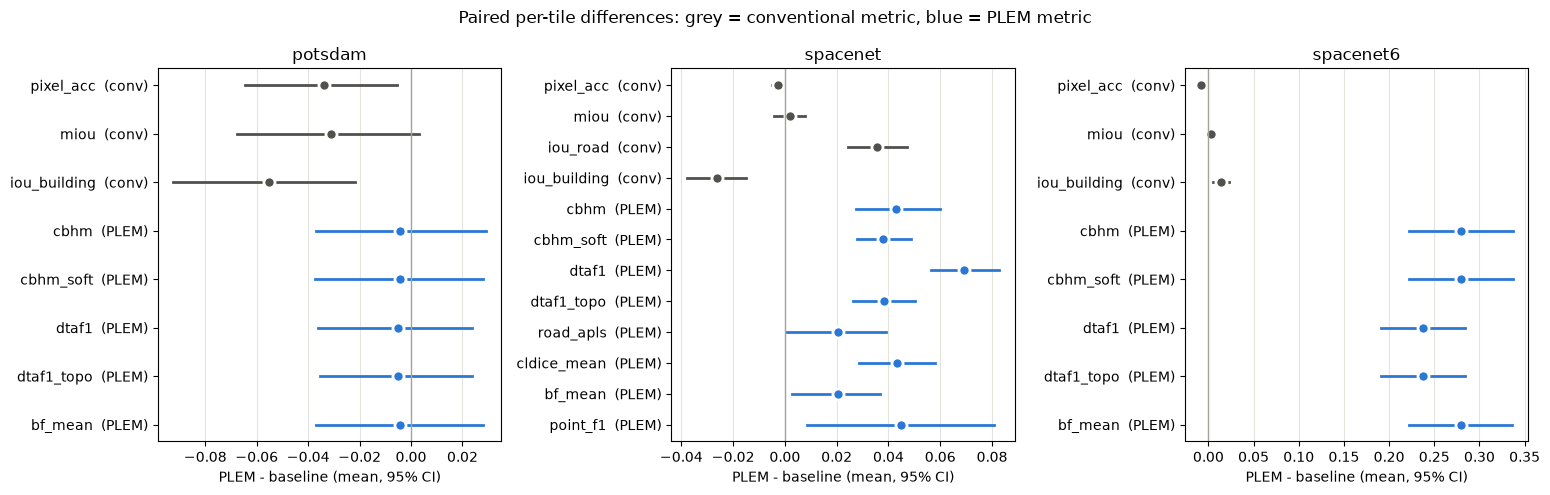

In [4]:
# One panel per source: mean paired difference with its 95% bootstrap CI, conventional metrics on
# top, PLEM's below. Zero = no difference; right of zero favours the joint loss.
sources = sorted(diffs["source"].unique())
fig, axes = plt.subplots(1, len(sources), figsize=(5.2 * len(sources), 5), sharex=False)
axes = np.atleast_1d(axes)
for ax, source in zip(axes, sources):
    sub = diffs[(diffs["source"] == source) & diffs["mean"].notna()].reset_index(drop=True)
    y = np.arange(len(sub))[::-1]
    for yi, (_, r) in zip(y, sub.iterrows()):
        color = "#52514e" if r["kind"] == "conventional" else "#2a78d6"
        ax.plot([r["ci_lo"], r["ci_hi"]], [yi, yi], color=color, linewidth=2)
        ax.plot(r["mean"], yi, "o", color=color, markersize=8,
                markeredgecolor="white", markeredgewidth=2)
    ax.axvline(0, color="#a3a29b", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{m}  ({k[:4]})" for m, k in zip(sub["metric"], sub["kind"])])
    ax.set_title(source)
    ax.set_xlabel("PLEM - baseline (mean, 95% CI)")
    ax.grid(axis="x", color="#e4e3dd", linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle("Paired per-tile differences: grey = conventional metric, blue = PLEM metric")
fig.tight_layout()
plt.show()

## 3. Do IoU and PLEM's metrics agree tile by tile?

Two views on SpaceNet (the only source with roads and intersections):

- **Rank agreement within each model:** Kendall's tau between per-tile mIoU and each PLEM metric.
  A low tau means the two kinds of metric order the same predictions differently.
- **Disagreement between models:** tiles where the change in mIoU and the change in `dtaf1_topo`
  (or `cbhm`) have opposite signs, i.e. the conventional metric prefers one model and PLEM's the
  other. The largest of these are drawn side by side in section 4.

In [5]:
tau_rows = []
for v in VARIANTS:
    sn = test[v][test[v]["source"] == "spacenet"]
    for m in PLEM + ["point_f1"]:
        ok = sn[["miou", m]].dropna()
        t, p = kendalltau(ok["miou"], ok[m]) if len(ok) > 2 else (np.nan, np.nan)
        tau_rows.append({"model": v, "metric": m, "kendall_tau_vs_miou": t, "p": p, "n": len(ok)})
display(pd.DataFrame(tau_rows).pivot(index="metric", columns="model", values="kendall_tau_vs_miou").round(3))

sn_pair = paired[paired["source"] == "spacenet"].copy()
for m in ["miou", "dtaf1_topo", "cbhm", "road_apls", "point_f1"]:
    sn_pair[f"d_{m}"] = sn_pair[f"{m}_p"] - sn_pair[f"{m}_b"]
for m in ["dtaf1_topo", "cbhm"]:
    opp = np.sign(sn_pair["d_miou"]) * np.sign(sn_pair[f"d_{m}"]) < 0
    print(f"tiles where d_mIoU and d_{m} disagree in sign: {int(opp.sum())}/{len(sn_pair)}")

sn_pair["disagreement"] = np.where(np.sign(sn_pair["d_miou"]) * np.sign(sn_pair["d_dtaf1_topo"]) < 0,
                                   (sn_pair["d_dtaf1_topo"] - sn_pair["d_miou"]).abs(), 0.0)
disagree = sn_pair.sort_values("disagreement", ascending=False)
display(disagree[disagree["disagreement"] > 0]
        [["tile", "d_miou", "d_dtaf1_topo", "d_cbhm", "d_road_apls", "d_point_f1",
          "miou_b", "miou_p", "dtaf1_topo_b", "dtaf1_topo_p"]].head(10).round(3))

model,baseline,plem
metric,,
bf_mean,0.638,0.590
cbhm,0.771,0.713
cbhm_soft,0.738,0.674
cldice_mean,0.667,0.638
dtaf1,0.803,0.731
dtaf1_topo,0.740,0.680
point_f1,0.299,0.294
road_apls,0.516,0.472


tiles where d_mIoU and d_dtaf1_topo disagree in sign: 30/83
tiles where d_mIoU and d_cbhm disagree in sign: 23/83


,tile,d_miou,d_dtaf1_topo,d_cbhm,d_road_apls,d_point_f1,miou_b,miou_p,dtaf1_topo_b,dtaf1_topo_p
57,Vegas_img1407,-0.088,0.109,-0.033,0.204,0.118,0.681,0.592,0.502,0.611
59,Shanghai_img1133,-0.003,0.175,0.028,0.272,-0.182,0.555,0.552,0.427,0.602
64,Shanghai_img1330,-0.024,0.132,0.021,0.195,0.000,0.616,0.592,0.509,0.642
5,Vegas_img1505,-0.006,0.135,0.018,0.221,0.095,0.624,0.618,0.560,0.695
37,Shanghai_img1854,-0.006,0.107,0.086,0.021,0.000,0.318,0.312,0.187,0.294
68,Shanghai_img1042,-0.035,0.076,-0.061,0.140,-0.208,0.691,0.656,0.561,0.637
12,Vegas_img1307,-0.026,0.079,-0.001,0.111,0.233,0.662,0.635,0.651,0.730
19,Paris_img268,-0.004,0.081,0.046,0.077,-0.286,0.587,0.582,0.448,0.529
44,Paris_img173,-0.005,0.079,0.011,0.061,0.023,0.599,0.594,0.429,0.508
25,Khartoum_img460,-0.012,0.063,-0.017,0.057,-0.105,0.612,0.600,0.423,0.487


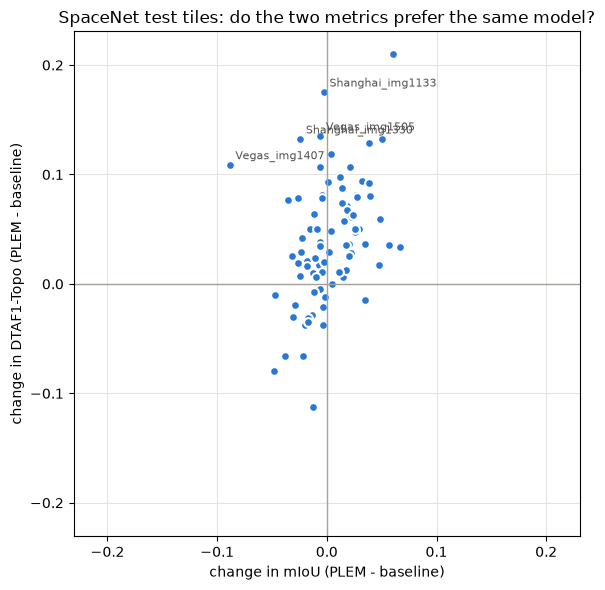

In [6]:
# Per-tile change in mIoU against change in DTAF1-Topo. Points off the diagonal quadrants
# (top-left, bottom-right) are tiles where the two kinds of metric prefer different models.
fig, ax = plt.subplots(figsize=(6, 6))
ax.axhline(0, color="#a3a29b", linewidth=1)
ax.axvline(0, color="#a3a29b", linewidth=1)
ax.scatter(sn_pair["d_miou"], sn_pair["d_dtaf1_topo"], s=40, color="#2a78d6",
           edgecolor="white", linewidth=1.5)
for _, r in disagree[disagree["disagreement"] > 0].head(4).iterrows():
    ax.annotate(r["tile"], (r["d_miou"], r["d_dtaf1_topo"]), fontsize=8, color="#52514e",
                xytext=(4, 4), textcoords="offset points")
lim = np.nanmax(np.abs(sn_pair[["d_miou", "d_dtaf1_topo"]].to_numpy())) * 1.1 or 1.0
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("change in mIoU (PLEM - baseline)")
ax.set_ylabel("change in DTAF1-Topo (PLEM - baseline)")
ax.set_title("SpaceNet test tiles: do the two metrics prefer the same model?")
ax.grid(color="#e4e3dd", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 4. Side by side: the tiles where the metrics disagree most

Image, ground truth, baseline and joint-model predictions (road red, building green, intersections
yellow; blue-grey = no public building labels). Needs `data/` and the prediction cache, so this
cell only draws on the machine that ran both jobs.

In [7]:
import torch
import torch.nn.functional as F


def overlay(label, point_mask=None, building_valid=None, point_radius=6):
    o = np.zeros((*label.shape, 3), dtype=np.uint8)
    if building_valid is not None:
        o[building_valid == 0] = [70, 90, 150]
    o[label == 1] = [255, 0, 0]
    o[label == 2] = [0, 255, 0]
    if point_mask is not None and point_mask.any():
        m = torch.from_numpy(point_mask.astype(np.float32))[None, None]
        big = F.max_pool2d(m, 2 * point_radius + 1, stride=1, padding=point_radius)[0, 0].numpy() > 0
        o[big] = [255, 255, 0]
    return o


def tile_npz(tile, source):
    hits = list((DATA_DIR / source).rglob(f"{tile}.npz")) if (DATA_DIR / source).is_dir() else []
    return np.load(hits[0]) if hits else None


def side_by_side(tiles, title):
    from datasets.intersections import points_to_mask
    rows = []
    for tile in tiles:
        src = paired.loc[paired["tile"] == tile, "source"].iloc[0]
        gt = tile_npz(tile, src)
        preds = {v: RESULTS_DIR / "preds" / v / f"{tile}.npz" for v in VARIANTS}
        if gt is None or not all(p.exists() for p in preds.values()):
            continue
        rows.append((tile, src, gt, {v: np.load(p) for v, p in preds.items()}))
    if not rows:
        print(f"({title}: image or prediction cache not available here -- skipped)")
        return
    fig, axes = plt.subplots(len(rows), 4, figsize=(18, 4.6 * len(rows)))
    axes = np.atleast_2d(axes)
    for ax_row, (tile, src, gt, pr) in zip(axes, rows):
        valid = gt["building_valid"] if "building_valid" in gt.files else None
        pts = (points_to_mask(gt["points"], gt["label"].shape, radius=2)
               if "points" in gt.files else None)
        s = paired.loc[paired["tile"] == tile].iloc[0]
        ax_row[0].imshow(gt["image"])
        ax_row[0].set_title(f"{tile} ({src})")
        ax_row[1].imshow(gt["image"])
        ax_row[1].imshow(overlay(np.where(gt["label"] == 3, 0, gt["label"]), pts, valid), alpha=0.5)
        ax_row[1].set_title("ground truth")
        for ax, v, suf in ((ax_row[2], "baseline", "_b"), (ax_row[3], "plem", "_p")):
            ax.imshow(gt["image"])
            ax.imshow(overlay(pr[v]["seg"], pr[v]["points"]), alpha=0.5)
            ax.set_title(f"{v}: mIoU {s['miou' + suf]:.2f}  DTAF1-Topo {s['dtaf1_topo' + suf]:.2f}\n"
                         f"APLS {s['road_apls' + suf]:.2f}  BF {s['bf_mean' + suf]:.2f}  "
                         f"pointF1 {s['point_f1' + suf]:.2f}")
        for ax in ax_row:
            ax.axis("off")
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    plt.show()


side_by_side(disagree[disagree["disagreement"] > 0]["tile"].head(4).tolist(),
             "Largest mIoU-vs-DTAF1-Topo disagreements (SpaceNet)")
side_by_side(sn_pair.sort_values("d_point_f1", ascending=False)["tile"].head(2).tolist(),
             "Largest intersection-F1 gains for the joint loss")

(Largest mIoU-vs-DTAF1-Topo disagreements (SpaceNet): image or prediction cache not available here -- skipped)
(Largest intersection-F1 gains for the joint loss: image or prediction cache not available here -- skipped)


## 5. Darkened input: both models on the same severity sweep

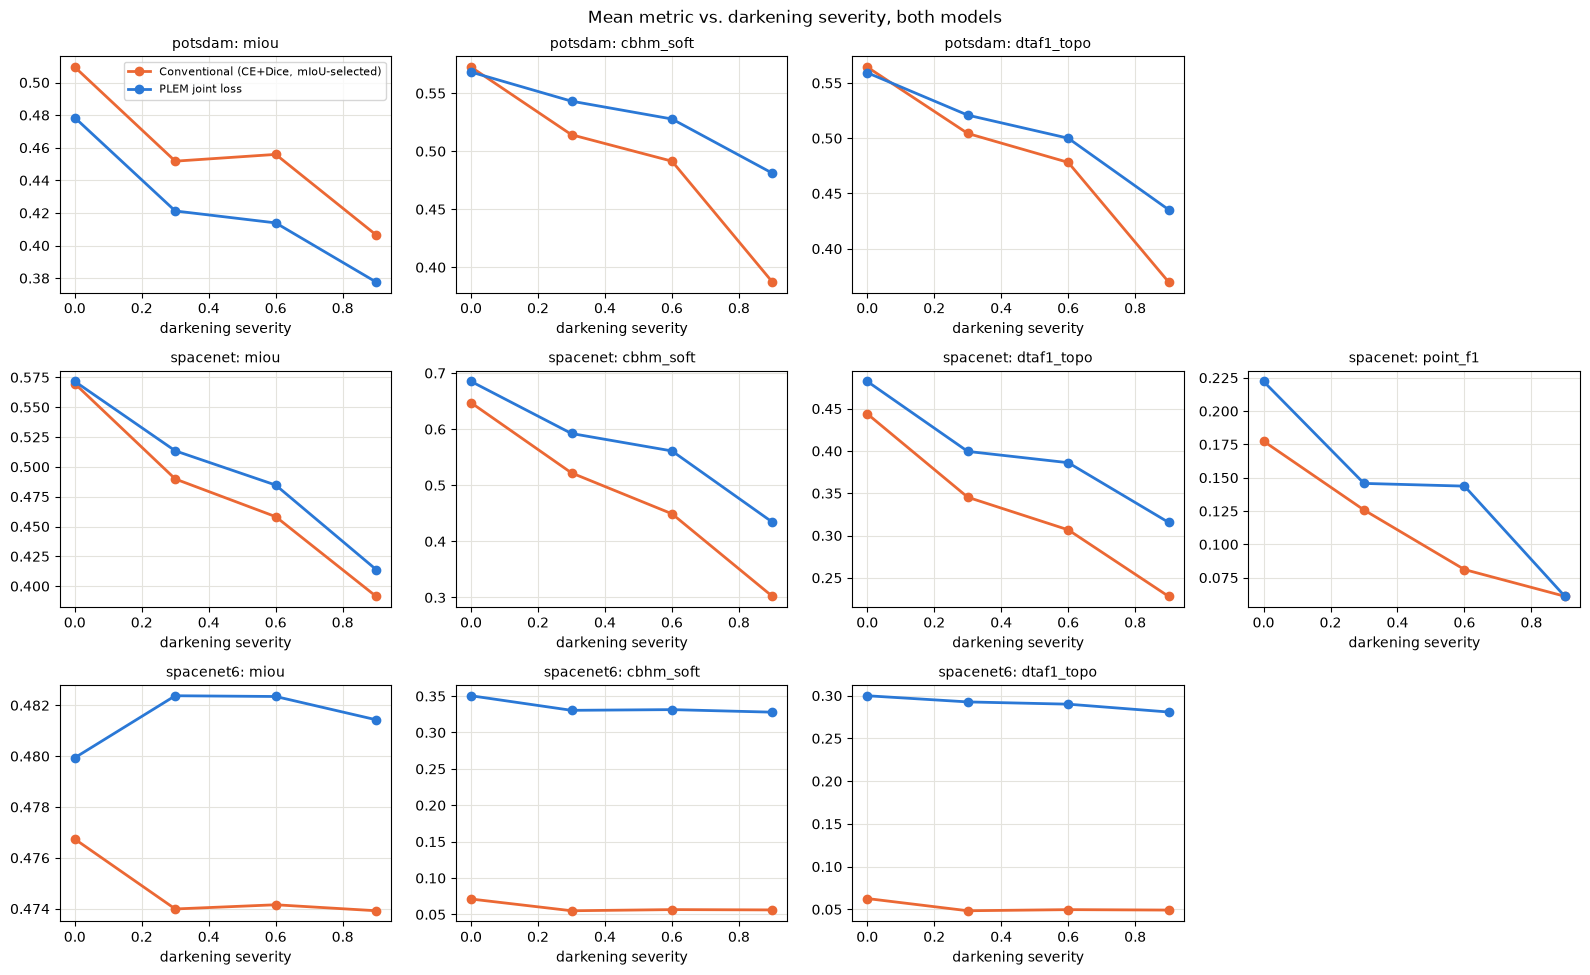

baseline                        plem                     
                       miou cbhm_soft dtaf1_topo   miou cbhm_soft dtaf1_topo
source    severity                                                          
potsdam   0.0         0.509     0.573      0.564  0.478     0.568      0.559
          0.3         0.452     0.514      0.504  0.421     0.543      0.521
          0.6         0.456     0.491      0.478  0.414     0.528      0.500
          0.9         0.406     0.387      0.370  0.378     0.481      0.435
spacenet  0.0         0.570     0.647      0.444  0.572     0.685      0.482
          0.3         0.490     0.522      0.345  0.513     0.592      0.399
          0.6         0.458     0.449      0.307  0.485     0.561      0.386
          0.9         0.391     0.302      0.228  0.414     0.434      0.316
spacenet6 0.0         0.477     0.071      0.063  0.480     0.350      0.300
          0.3         0.474     0.055      0.048  0.482     0.330      0.293
          0.6         0.474     0.057      0.050  0.482     0.331      0.290
          0.9         0.474     0.056      0.049  0.481     0.328      0.281

In [8]:
DARK_METRICS = ["miou", "cbhm_soft", "dtaf1_topo", "point_f1"]
sources = sorted(dark["plem"]["source"].unique())
fig, axes = plt.subplots(len(sources), len(DARK_METRICS), figsize=(4 * len(DARK_METRICS), 3.3 * len(sources)),
                         squeeze=False)
for i, source in enumerate(sources):
    for j, m in enumerate(DARK_METRICS):
        ax = axes[i, j]
        if m == "point_f1" and source != "spacenet":
            ax.axis("off")  # intersections are only labelled on SpaceNet
            continue
        for v in VARIANTS:
            sub = dark[v][dark[v]["source"] == source]
            means = sub.groupby("severity")[m].mean()
            if means.notna().any():
                ax.plot(means.index, means.values, marker="o", markersize=6, linewidth=2,
                        color=COLORS[v], label=LABELS[v])
        ax.set_title(f"{source}: {m}", fontsize=10)
        ax.set_xlabel("darkening severity")
        ax.grid(color="#e4e3dd", linewidth=0.8)
        ax.set_axisbelow(True)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Mean metric vs. darkening severity, both models")
fig.tight_layout()
plt.show()

dark_table = pd.concat({v: dark[v].groupby(["source", "severity"])[DARK_METRICS[:3]].mean()
                        for v in VARIANTS}, axis=1)
display(dark_table.round(3))

## 6. Findings (CARC, Oct 2026; one seed per model, same `SEED=0`, same data, split and epoch budget)

Both models trained the full 40 epochs (best epoch: baseline 36 by validation mIoU, joint 38 by
`val_select`). The joint model's numbers reproduce run 6 exactly (SpaceNet `cbhm_soft` 0.685,
547 predicted / 270 matched intersections). Test tiles: 83 SpaceNet, 30 Potsdam, 43 SpaceNet6, paired.

**Metric claim: supported.** On SpaceNet the conventional metrics call the two models a tie,
while every PLEM metric separates them:

- mIoU 0.570 vs 0.572 (paired difference +0.002, 95% CI −0.004 to +0.008, p = 0.64); pixel
  accuracy is 0.003 *lower* for the joint model.
- `dtaf1` +0.069, `cldice_mean` +0.043, `cbhm` +0.043, `dtaf1_topo` +0.038, `cbhm_soft` +0.038,
  road APLS +0.020, `bf_mean` +0.020, all with CIs excluding 0 (p ≤ 0.002).
- The tie in mIoU hides two opposite moves: road IoU +0.036 and building IoU −0.026 for the joint
  model. On buildings IoU and BF point in **opposite** directions (IoU favours the baseline, BF
  favours the joint model), i.e. the joint model's footprints overlap less but have better-placed
  boundaries.
- Tile by tile, ΔmIoU and Δ`dtaf1_topo` disagree in sign on 30 of 83 tiles (Δ`cbhm`: 23 of 83).
  The largest case, `Vegas_img1407`, loses 0.088 mIoU and gains 0.109 `dtaf1_topo` (APLS +0.20).
- Within each model, Kendall's tau between per-tile mIoU and the PLEM metrics is 0.47–0.80 for
  segmentation metrics but only ~0.30 for intersection F1: the two kinds of metric are related
  but rank tiles differently.
- Intersections: pixel IoU of the stamped squares is 0.024 (baseline) vs 0.033 (joint), a
  number that says nothing about detection; the matched-instance F1 is 0.218 vs 0.279.

**SpaceNet6 is the extreme case.** mIoU 0.477 vs 0.480 and building IoU 0.023 vs 0.037 (both
models fail by IoU), but `bf_mean`/`cbhm` 0.071 vs 0.350. The baseline predicts almost no
buildings (148K px over 43 tiles, 4 tiles empty); the joint model predicts 521K building px on
every tile, and 544K road px along building rows. Its footprints land near the GT boundaries
(within BF's tolerance) but barely overlap them. A plausible but unverified cause is SAR layover,
which displaces building returns from their footprints. Read this as "the joint model finds
buildings in SAR that pixel overlap does not credit", not as a good SAR building detector: both
models are poor on this source.

**Loss claim: supported on SpaceNet and SpaceNet6, not on Potsdam.**

- SpaceNet: joint model better on all PLEM metrics (above); intersection micro F1 0.279 vs the
  baseline's 0.218 calibrated (0.195 at its default 0.5). Per-tile mean F1 +0.045 (CI +0.009 to
  +0.081, p = 0.015). The baseline is not worse everywhere on points: its probabilities are more
  spread out, so its recall at low thresholds reaches 0.43 against the joint model's 0.62 ceiling
  at a far lower precision, and its validation-calibrated threshold (0.7) gives a near-1
  predicted/real ratio (0.85 vs 0.39).
- Potsdam (building only): no difference on PLEM metrics (`cbhm` −0.004, CI −0.037 to +0.029);
  the **baseline** is better on building IoU (−0.055 for the joint model, p = 0.02) and pixel
  accuracy. Here the metrics again disagree, in the conventional model's favour on IoU.
- Darkened input: the joint model degrades less. At severity 0.9, SpaceNet `cbhm_soft` 0.434 vs
  0.302 and Potsdam 0.481 vs 0.387, although the two start level on Potsdam; mIoU shows a much
  smaller gap (SpaceNet 0.414 vs 0.391) and on Potsdam still favours the baseline at every severity.

**Caveats.** One seed per model; the per-tile CIs capture test-tile variation, not training
variation. The two models use different selection rules by design (each its own field's
convention). The baseline's BCE `pos_weight` was capped at 100 (raw ratio 5,770). The tile-level
p-values are uncorrected for the ~28 comparisons; the SpaceNet and SpaceNet6 PLEM-metric
results stay significant under Bonferroni (threshold 0.0018) except road APLS (p = 0.0020, at the line);
the point-F1 and Potsdam IoU results do not.